<a href="https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-1/02-tu-primer-modelo-la-recta/solucion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# Solución 1.2 · Tu primer modelo: la recta

**Serie:** Del Excel al Machine Learning · **Temporada 1** · 🎬 Video próximamente

Estas son las respuestas del ejercicio. Si la tuya es distinta pero da el mismo resultado, ¡también está bien! En programación suele haber más de una forma de llegar a la respuesta.

### Prepara los datos

Ejecuta estas tres celdas. `mensual` tiene una fila por cliente y mes, ya con el tipo de cliente. Debe tener 6,459 filas.

Algunos ejercicios usan variables de los anteriores, así que **ejecútalos en orden**.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression

DATOS = "https://raw.githubusercontent.com/PercyTechX/del-excel-al-ml/main/datos/"

In [2]:
def por_cliente_y_mes(ventas):
    """Una fila por cliente y mes en que compró, con sus líneas de pedido y su monto."""
    meses = ventas["fecha"].str[:7]
    return (
        ventas.groupby(["id_cliente", meses])
        .agg(lineas=("total", "size"), total=("total", "sum"))
        .reset_index()
    )

In [3]:
ventas = pd.read_csv(DATOS + "ventas.csv")
clientes = pd.read_csv(DATOS + "clientes.csv")

mensual = por_cliente_y_mes(ventas)
mensual = pd.merge(mensual, clientes[["id_cliente", "tipo"]], on="id_cliente", how="left")

mensual.shape

(6459, 5)

### 1. Las bodegas

Filtra las filas de `Bodega` y guárdalas en `bodegas`. Haz su gráfico de dispersión, con título y ejes.

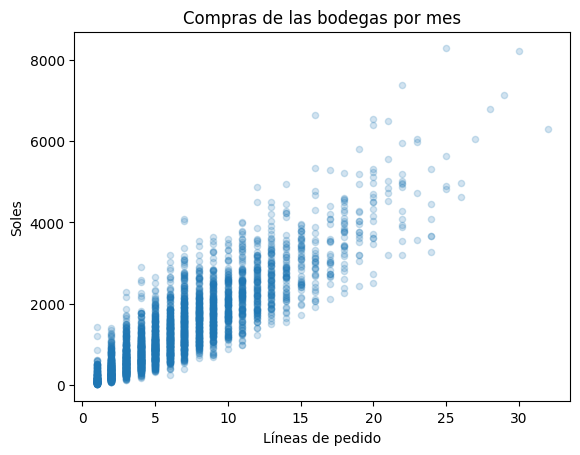

In [4]:
bodegas = mensual[mensual["tipo"] == "Bodega"]

bodegas.plot(
    kind="scatter",
    x="lineas",
    y="total",
    alpha=0.2,
    title="Compras de las bodegas por mes",
    xlabel="Líneas de pedido",
    ylabel="Soles",
)
plt.show()

### 2. Su recta

Entrena una regresión con `bodegas`, guárdala en `modelo_bodegas` y muestra su pendiente, su punto de corte y su R², redondeados. La pendiente debe ser cercana a `207`.

¿Qué significa ese número para un vendedor? Responde en un comentario.

In [5]:
modelo_bodegas = LinearRegression()
modelo_bodegas.fit(bodegas[["lineas"]], bodegas["total"])

print(modelo_bodegas.coef_.round(1))
print(modelo_bodegas.intercept_.round(1))
print(round(modelo_bodegas.score(bodegas[["lineas"]], bodegas["total"]), 2))

# Cada línea adicional de una bodega se asocia con unos S/ 207 más en el mes.

[207.4]
-14.2
0.77


### 3. Los minimarkets

Repite lo mismo con los `Minimarket`, y guarda el modelo en `modelo_minimarkets`. La pendiente debe ser cercana a `369`. ¿Por qué una sola recta para todos, con pendiente 325.5, no describe bien a ninguno de los dos? Responde en un comentario.

In [6]:
minimarkets = mensual[mensual["tipo"] == "Minimarket"]

modelo_minimarkets = LinearRegression()
modelo_minimarkets.fit(minimarkets[["lineas"]], minimarkets["total"])

print(modelo_minimarkets.coef_.round(1))
print(modelo_minimarkets.intercept_.round(1))
print(round(modelo_minimarkets.score(minimarkets[["lineas"]], minimarkets["total"]), 2))

# La recta general promedia clientes distintos: en promedio, se pasa con las bodegas
# y se queda corta con los minimarkets.

[368.5]
-68.7
0.83


### 4. Una predicción con sentido

Con la recta de las bodegas y con la de los minimarkets, predice el monto de 10 líneas. Deben dar `2059.5` y `3616.4`. ¿Cuánto cambia?

In [7]:
nuevo = pd.DataFrame({"lineas": [10]})

print(modelo_bodegas.predict(nuevo).round(1))
print(modelo_minimarkets.predict(nuevo).round(1))

# Cambia en unos S/ 1,557: una misma cantidad de líneas significa montos muy distintos.

[2059.5]
[3616.4]


### 5. Otra variable

Esta tabla no tiene la cantidad de presentaciones. Agrégala: suma `cantidad` por cliente y mes, y compara su R² con el de las líneas. Para que puedas enfocarte en el modelo, esta parte ya está lista:

```python
meses = ventas["fecha"].str[:7]
cantidades = ventas.groupby(["id_cliente", meses])["cantidad"].sum().reset_index()
con_cantidad = pd.merge(mensual, cantidades, on=["id_cliente", "fecha"], how="left")
```

Copia eso y entrena con `con_cantidad[["cantidad"]]`. Su R² debe ser cercano a `0.94`, frente al `0.76` de las líneas en la clase. ¿Por qué es tan alto? ¿Te sirve para saber cuánto comprará alguien el próximo mes? Responde en un comentario.

In [8]:
meses = ventas["fecha"].str[:7]
cantidades = ventas.groupby(["id_cliente", meses])["cantidad"].sum().reset_index()
con_cantidad = pd.merge(mensual, cantidades, on=["id_cliente", "fecha"], how="left")

modelo_cantidad = LinearRegression()
modelo_cantidad.fit(con_cantidad[["cantidad"]], con_cantidad["total"])

print(round(modelo_cantidad.score(con_cantidad[["cantidad"]], con_cantidad["total"]), 2))

# Es alto porque el total sale casi directo de la cantidad por el precio.
# No sirve para el próximo mes: la cantidad de ese mes todavía no se conoce.

0.94


## 🎉 ¡Bien hecho!

Nos vemos en el **episodio 1.3: ¿Funciona con datos nuevos?**

---

*Del Excel al Machine Learning* · por [Percy Nazario](https://www.linkedin.com/in/percy-nazario/) · [Repositorio](https://github.com/PercyTechX/del-excel-al-ml) · Contenido bajo licencia CC BY 4.0